 identidad_%  llamados_ARG  recall  precision    f1  accuracy
          20           785   0.760      0.968 0.852     0.868
          30           736   0.720      0.978 0.829     0.852
          40           525   0.516      0.983 0.677     0.754
          50           353   0.351      0.994 0.519     0.674
          60           292   0.292      1.000 0.452     0.646
          70           246   0.246      1.000 0.395     0.623


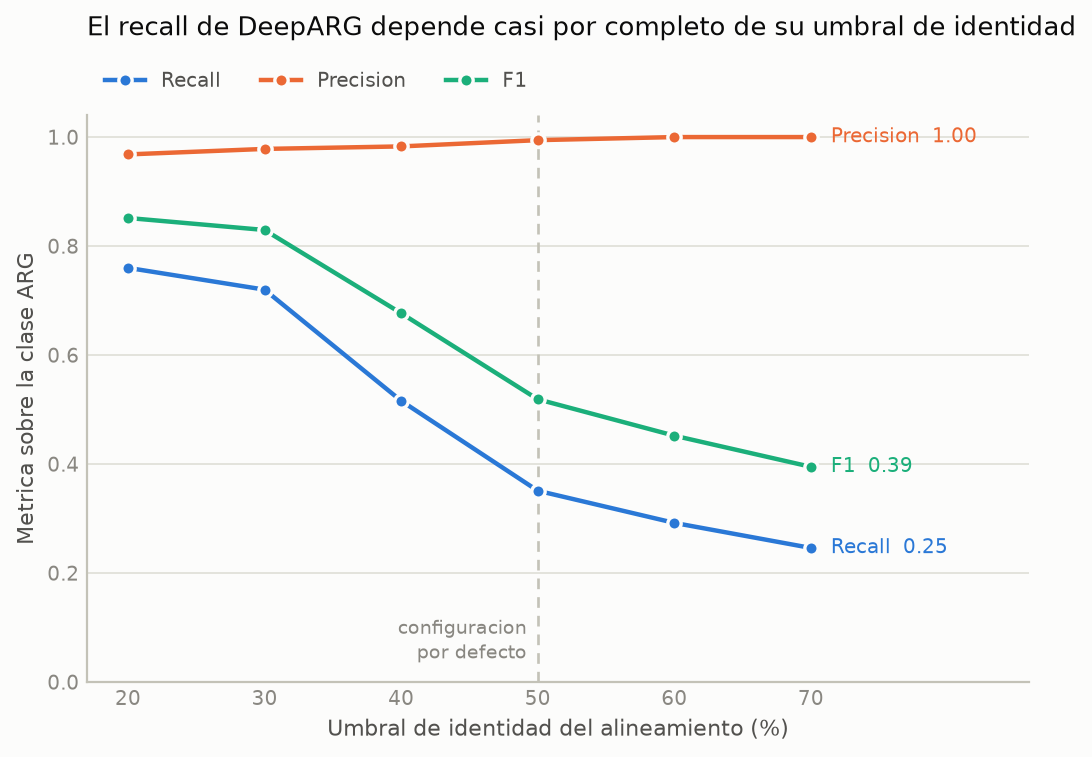

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

BASE     = "/mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias"
LABELS   = f"{BASE}/data/interim/muestra_genes_labels.tsv"
UMBRALES = [20, 30, 40, 50, 60, 70]

faltan = [u for u in UMBRALES if not Path(f"{BASE}/results/deeparg_id{u}.mapping.ARG").exists()]
if faltan:
    raise FileNotFoundError(f"Faltan las salidas de DeepARG para los umbrales: {faltan}")

truth = pd.read_csv(LABELS, sep="\t")
gid_col, lab_col = truth.columns[0], truth.columns[1]
truth = truth[[gid_col, lab_col]].rename(columns={gid_col: "gid", lab_col: "y_true"})
truth["y_true"] = truth["y_true"].astype(int)
truth["key"] = truth["gid"].str.split().str[0]

filas = []
for idv in UMBRALES:
    det = pd.read_csv(f"{BASE}/results/deeparg_id{idv}.mapping.ARG", sep="\t")
    ids = set(det[det.columns[3]].astype(str).unique())
    y_pred = truth["key"].isin(ids).astype(int)
    p, r, f, _ = precision_recall_fscore_support(truth["y_true"], y_pred, labels=[1], average=None)
    filas.append({"identidad_%": idv, "llamados_ARG": int(y_pred.sum()),
                  "recall": r[0], "precision": p[0], "f1": f[0],
                  "accuracy": accuracy_score(truth["y_true"], y_pred)})

tabla = pd.DataFrame(filas)
print(tabla.round(3).to_string(index=False))
tabla.to_csv(f"{BASE}/results/curva_deeparg_identidad.csv", index=False)

# ---------------- figura ----------------
SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
COLS = {"recall": "#2a78d6", "precision": "#eb6834", "f1": "#1baf7a"}
ETIQ = {"recall": "Recall", "precision": "Precision", "f1": "F1"}

fig, ax = plt.subplots(figsize=(7.6, 4.6), dpi=160)
fig.patch.set_facecolor(SURF); ax.set_facecolor(SURF)

ax.axvline(50, color=AXIS, lw=1.2, ls=(0, (4, 3)), zorder=1)
ax.text(49.2, 0.03, "configuracion\npor defecto", color=MUTED, fontsize=8.5,
        ha="right", va="bottom", linespacing=1.3)

for m in ["recall", "precision", "f1"]:
    ax.plot(tabla["identidad_%"], tabla[m], color=COLS[m], lw=2,
            marker="o", ms=6, mec=SURF, mew=1.5, zorder=3, label=ETIQ[m])
    ax.annotate(f"{ETIQ[m]}  {tabla[m].iloc[-1]:.2f}",
                (tabla["identidad_%"].iloc[-1], tabla[m].iloc[-1]),
                textcoords="offset points", xytext=(9, 0),
                ha="left", va="center", color=COLS[m], fontsize=9)

ax.set_xlim(17, 86); ax.set_ylim(0, 1.04)
ax.set_xticks(UMBRALES)
ax.set_xlabel("Umbral de identidad del alineamiento (%)", color=INK2, fontsize=10)
ax.set_ylabel("Metrica sobre la clase ARG", color=INK2, fontsize=10)
ax.set_title("El recall de DeepARG depende casi por completo de su umbral de identidad",
             color=INK, fontsize=11.5, loc="left", pad=36)

ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
for s in ("top", "right"): ax.spines[s].set_visible(False)
for s in ("left", "bottom"):
    ax.spines[s].set_color(AXIS); ax.spines[s].set_linewidth(1)
ax.tick_params(colors=MUTED, labelsize=9, length=0)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncol=3,
          frameon=False, fontsize=9, labelcolor=INK2)

plt.savefig(f"{BASE}/results/fig_deeparg_identidad.png",  dpi=300, facecolor=SURF, bbox_inches="tight")
plt.savefig(f"{BASE}/results/fig_deeparg_identidad.tiff", dpi=300, facecolor=SURF, bbox_inches="tight")
plt.show()

Genes positivos: 1000

=== Recall por base de datos de origen ===
               genes  ARGNet_OR  DeepARG_id50  DeepARG_id30
fuente                                                     
ResFinderFG      475      0.204         0.067         0.663
CARD             328      0.954         0.607         0.793
MEGARes          112      0.973         0.732         0.777
AMRFinderPlus     49      0.714         0.367         0.673
ResFinder         25      0.960         0.720         0.840
ARGANNOT          11      1.000         0.182         0.364 

=== ResFinderFG frente al resto ===
                   genes  ARGNet_OR  DeepARG_id50  DeepARG_id30
grupo                                                          
Las otras 5 bases    525      0.937         0.608         0.771
ResFinderFG          475      0.204         0.067         0.663


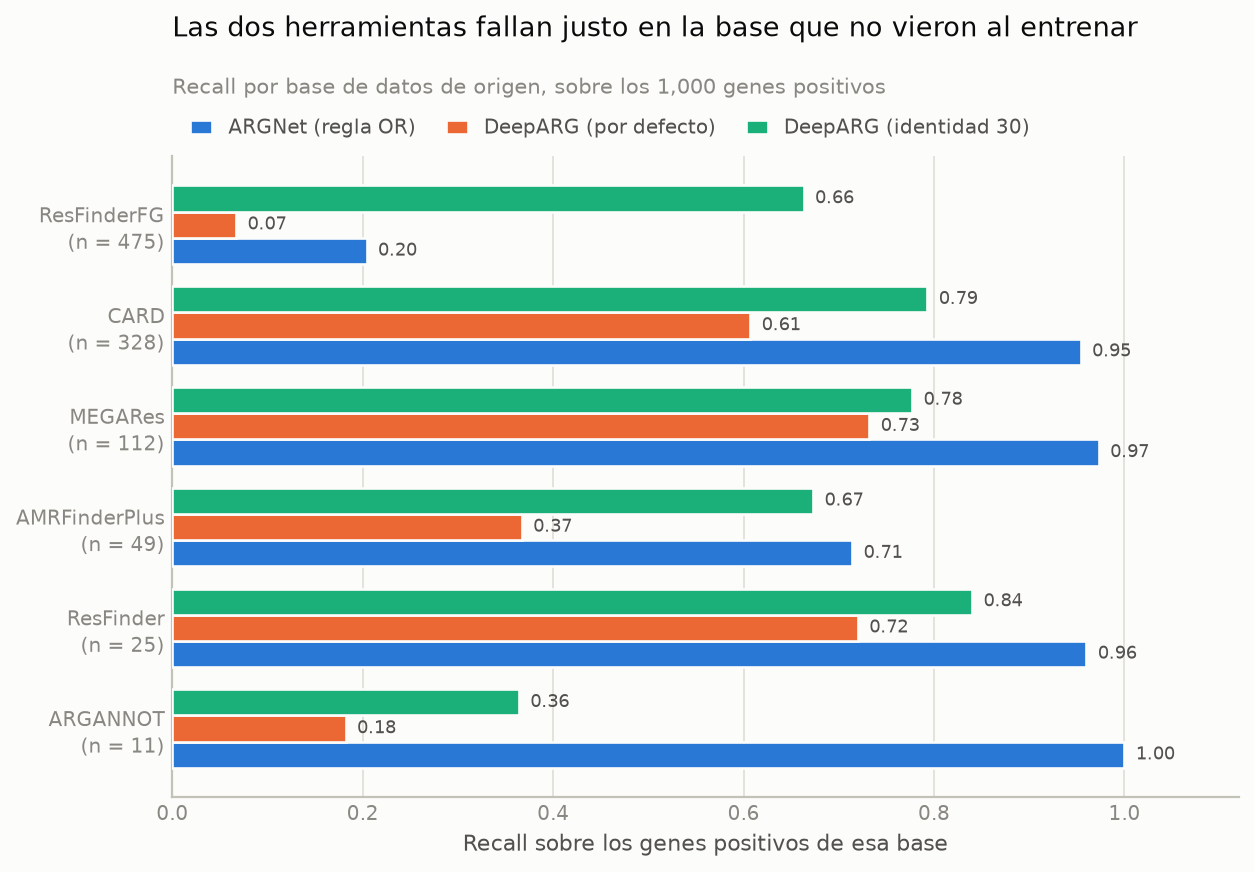

In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

BASE       = "/mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias"
LABELS     = f"{BASE}/data/interim/muestra_genes_labels.tsv"
ARGNET_OUT = "/home/r4gbi/ARGNet/results/argnet_reads150.txt"

# ---------- genes positivos, con su base de origen ----------
truth = pd.read_csv(LABELS, sep="\t")
gid_col, lab_col = truth.columns[0], truth.columns[1]
truth = truth[[gid_col, lab_col]].rename(columns={gid_col: "gid", lab_col: "y_true"})
truth["y_true"] = truth["y_true"].astype(int)

pos = truth[truth["y_true"] == 1].copy()
pos["fuente"] = pos["gid"].str.split("|").str[0]
print(f"Genes positivos: {len(pos)}\n")

# ---------- ARGNet, nivel gen con regla OR ----------
reads = pd.read_csv(ARGNET_OUT, sep=None, engine="python")
reads["pred_bin"] = (reads["ARG_prediction"].astype(str).str.strip().str.upper() == "ARG").astype(int)
reads["gid"] = reads["test_id"].astype(str).str.split("__r").str[0]
g_or = reads.groupby("gid")["pred_bin"].max()
pos["ARGNet_OR"] = pos["gid"].isin(set(g_or[g_or == 1].index)).astype(int)

# ---------- DeepARG, dos umbrales ----------
COLS = ["ARGNet_OR"]
for idv in (50, 30):
    ruta = Path(f"{BASE}/results/deeparg_id{idv}.mapping.ARG")
    if not ruta.exists():
        print(f"AVISO: falta {ruta.name}, se omite esa columna")
        continue
    det = pd.read_csv(ruta, sep="\t")
    ids = set(det[det.columns[3]].astype(str).unique())
    col = f"DeepARG_id{idv}"
    pos[col] = pos["gid"].isin(ids).astype(int)
    COLS.append(col)

# ---------- tabla por base ----------
t = pos.groupby("fuente").agg(genes=("gid", "size"), **{c: (c, "sum") for c in COLS})
for c in COLS:
    t[c] = (t[c] / t["genes"]).round(3)
t = t.sort_values("genes", ascending=False)
print("=== Recall por base de datos de origen ===")
print(t.to_string(), "\n")

# ---------- el contraste que importa ----------
pos["grupo"] = np.where(pos["fuente"] == "ResFinderFG", "ResFinderFG", "Las otras 5 bases")
resumen = pos.groupby("grupo").agg(genes=("gid", "size"),
                                   **{c: (c, "mean") for c in COLS}).round(3)
print("=== ResFinderFG frente al resto ===")
print(resumen.to_string())
t.to_csv(f"{BASE}/results/recall_por_base.csv")

# ---------- figura ----------
SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
PAL = {"ARGNet_OR": "#2a78d6", "DeepARG_id50": "#eb6834", "DeepARG_id30": "#1baf7a"}
NOM = {"ARGNet_OR": "ARGNet (regla OR)", "DeepARG_id50": "DeepARG (por defecto)",
       "DeepARG_id30": "DeepARG (identidad 30)"}

tp = t.sort_values("genes")
y, h = np.arange(len(tp)), 0.78 / len(COLS)

fig, ax = plt.subplots(figsize=(8.6, 5.2), dpi=160)
fig.patch.set_facecolor(SURF); ax.set_facecolor(SURF)

for i, c in enumerate(COLS):
    barras = ax.barh(y + (i - (len(COLS) - 1) / 2) * h, tp[c], h, color=PAL[c],
                     label=NOM[c], edgecolor=SURF, linewidth=1.2, zorder=3)
    for b, v in zip(barras, tp[c]):
        ax.text(v + 0.012, b.get_y() + b.get_height() / 2, f"{v:.2f}",
                va="center", ha="left", fontsize=8, color=INK2)

ax.set_yticks(y)
ax.set_yticklabels([f"{i}\n(n = {int(n)})" for i, n in zip(tp.index, tp["genes"])],
                   fontsize=9, color=INK2, linespacing=1.4)
ax.set_xlim(0, 1.12)
ax.set_xlabel("Recall sobre los genes positivos de esa base", color=INK2, fontsize=10)
ax.set_title("Las dos herramientas fallan justo en la base que no vieron al entrenar",
             color=INK, fontsize=12, loc="left", pad=54)
ax.text(0, 1.09, "Recall por base de datos de origen, sobre los 1,000 genes positivos",
        transform=ax.transAxes, color=MUTED, fontsize=9.5, va="bottom")

ax.grid(axis="x", color=GRID, lw=0.8, zorder=0); ax.set_axisbelow(True)
for s in ("top", "right"): ax.spines[s].set_visible(False)
for s in ("left", "bottom"):
    ax.spines[s].set_color(AXIS); ax.spines[s].set_linewidth(1)
ax.tick_params(colors=MUTED, labelsize=9, length=0)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, frameon=False,
          fontsize=9, labelcolor=INK2, handlelength=1.1, columnspacing=1.5)

plt.savefig(f"{BASE}/results/fig_recall_por_base.png",  dpi=300, facecolor=SURF, bbox_inches="tight")
plt.savefig(f"{BASE}/results/fig_recall_por_base.tiff", dpi=300, facecolor=SURF, bbox_inches="tight")
plt.show()

findfont: Failed to find font weight semibold, now using 700.


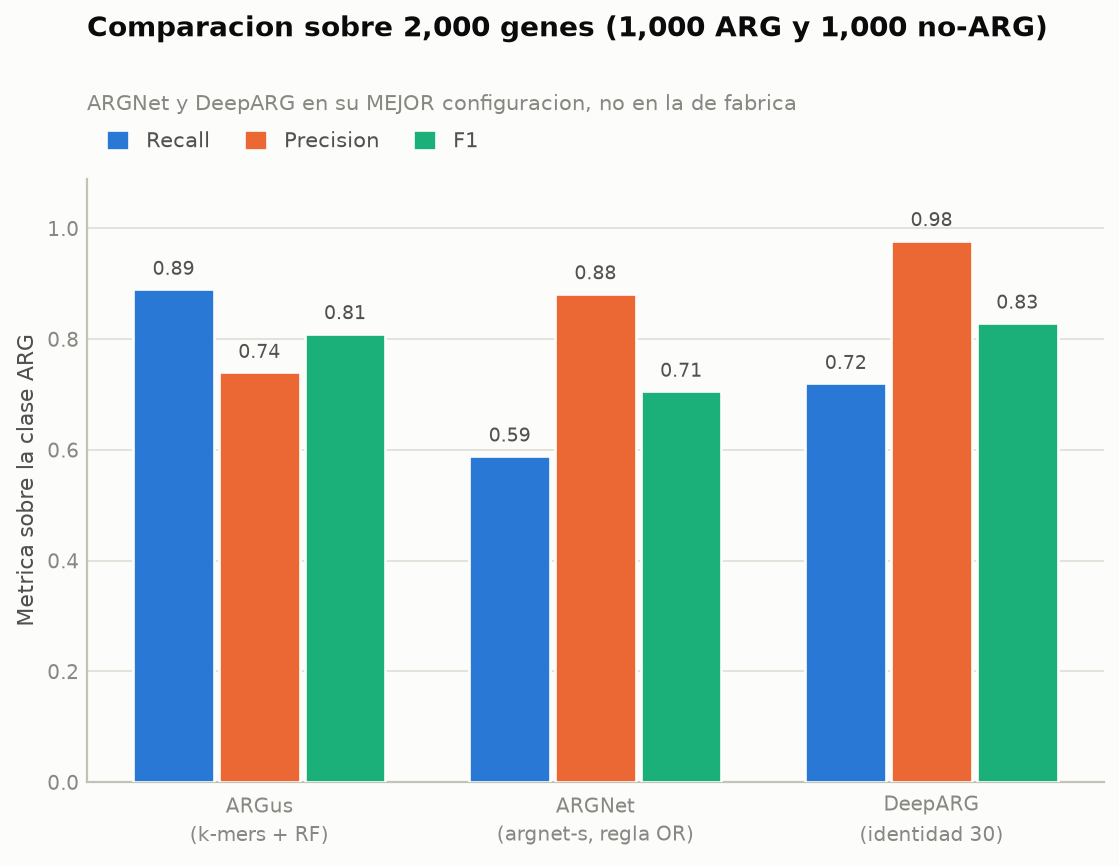

In [3]:
import matplotlib.pyplot as plt
import numpy as np

BASE = "/mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias"

METODOS = [
    "ARGus\n(k-mers + RF)",
    "ARGNet\n(argnet-s, regla OR)",
    "DeepARG\n(identidad 30)",
]
DATOS = {
    "Recall":    [0.890, 0.589, 0.720],
    "Precision": [0.740, 0.882, 0.978],
    "F1":        [0.810, 0.706, 0.829],
}

SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
COLS = {"Recall": "#2a78d6", "Precision": "#eb6834", "F1": "#1baf7a"}

x   = np.arange(len(METODOS))
w   = 0.24
off = {"Recall": -0.255, "Precision": 0.0, "F1": 0.255}

fig, ax = plt.subplots(figsize=(8.2, 4.9), dpi=160)
fig.patch.set_facecolor(SURF); ax.set_facecolor(SURF)

for serie, valores in DATOS.items():
    barras = ax.bar(x + off[serie], valores, w, color=COLS[serie], label=serie,
                    edgecolor=SURF, linewidth=1.2, zorder=3)
    for b, v in zip(barras, valores):
        ax.text(b.get_x() + b.get_width()/2, v + 0.018, f"{v:.2f}",
                ha="center", va="bottom", fontsize=8.5, color=INK2)

ax.set_ylim(0, 1.09)
ax.set_xticks(x)
ax.set_xticklabels(METODOS, fontsize=9.5, color=INK2, linespacing=1.5)
ax.set_ylabel("Metrica sobre la clase ARG", color=INK2, fontsize=10)

ax.set_title("Comparacion sobre 2,000 genes (1,000 ARG y 1,000 no-ARG)",
             color=INK, fontsize=12.5, loc="left", pad=64, fontweight="semibold")
ax.text(0, 1.105, "ARGNet y DeepARG en su MEJOR configuracion, no en la de fabrica",
        transform=ax.transAxes, color=MUTED, fontsize=9.5, va="bottom")

ax.grid(axis="y", color=GRID, lw=0.8, zorder=0); ax.set_axisbelow(True)
for s in ("top", "right"): ax.spines[s].set_visible(False)
for s in ("left", "bottom"):
    ax.spines[s].set_color(AXIS); ax.spines[s].set_linewidth(1)
ax.tick_params(colors=MUTED, labelsize=9, length=0)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.012), ncol=3, frameon=False,
          fontsize=9.5, labelcolor=INK2, handlelength=1.1, handleheight=1.1,
          columnspacing=1.6)

plt.savefig(f"{BASE}/results/fig_comparacion_3modelos.png",  dpi=300, facecolor=SURF, bbox_inches="tight")
plt.savefig(f"{BASE}/results/fig_comparacion_3modelos.tiff", dpi=300, facecolor=SURF, bbox_inches="tight")
plt.show()